#  Statistical Inference

This notebook uses samples and statistical tests to support business decisions instead of relying only on descriptive analysis.

##  Imports and data

###  Upload data

In [3]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_merged_dataset.csv to cleaned_merged_dataset.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

sns.set_theme(style="whitegrid")

analysis_data = pd.read_csv(
    "/content/cleaned_merged_dataset.csv"
)

analysis_data["order_date"] = pd.to_datetime(
    analysis_data["order_date"]
)

## Random sampling

In [8]:
sample_size = min(300, len(analysis_data))

sample_data = analysis_data.sample(
    n=sample_size,
    random_state=42
)

print("Sample size:", len(sample_data))
display(sample_data.head())

Sample size: 300


,order_item_id,order_id,order_date,customer_id,product_id,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_mode,...,avg_rating,review_count,year,month,month_name,day,day_name,weekday,is_weekend,profit_margin_pct
505,ITEM-03659,ORD-02685,2026-02-07,C-0411,AMZ-1004,1,39.99,10,35.99,Standard,...,4.6,1890,2026,2,February,7,Saturday,5,True,43.039733
1611,ITEM-00868,ORD-00627,2026-05-01,C-0381,AMZ-2003,2,149.00,0,149.00,Next-Day Prime,...,4.4,620,2026,5,May,1,Friday,4,False,57.550336
3107,ITEM-04245,ORD-03125,2026-07-27,C-0506,AMZ-2002,1,18.99,0,18.99,Same-Day,...,4.8,3120,2026,7,July,27,Monday,0,False,52.606635
511,ITEM-02797,ORD-02056,2026-02-08,C-0587,AMZ-1003,1,24.99,0,24.99,Next-Day Prime,...,4.6,2150,2026,2,February,8,Sunday,6,True,51.980792
1467,ITEM-01597,ORD-01167,2026-04-20,C-0742,AMZ-1002,1,119.99,5,113.99,Next-Day Express,...,4.5,860,2026,4,April,20,Monday,0,False,56.575138


##  Sample statistics

In [9]:
print("Population mean revenue:",
      analysis_data["total_revenue_gbp"].mean())

print("Sample mean revenue:",
      sample_data["total_revenue_gbp"].mean())

print("Population mean profit:",
      analysis_data["net_profit_gbp"].mean())

print("Sample mean profit:",
      sample_data["net_profit_gbp"].mean())

Population mean revenue: 47.16065716911765
Sample mean revenue: 48.10596666666667
Population mean profit: 25.971089154411768
Sample mean profit: 26.699299999999997


##  Confidence interval for revenue

Calculate a 95% confidence interval for mean line-level revenue using a t-distribution.

In [10]:
revenue = analysis_data["total_revenue_gbp"].dropna()

n = len(revenue)
mean_revenue = revenue.mean()
std_revenue = revenue.std(ddof=1)

standard_error = std_revenue / np.sqrt(n)

confidence_level = 0.95
t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    df=n - 1
)

margin_error = t_critical * standard_error

lower_bound = mean_revenue - margin_error
upper_bound = mean_revenue + margin_error

print("Mean revenue:", mean_revenue)
print("95% Confidence Interval:")
print("Lower:", lower_bound)
print("Upper:", upper_bound)

Mean revenue: 47.16065716911765
95% Confidence Interval:
Lower: 45.838220986167705
Upper: 48.48309335206759


##  Visualize confidence interval

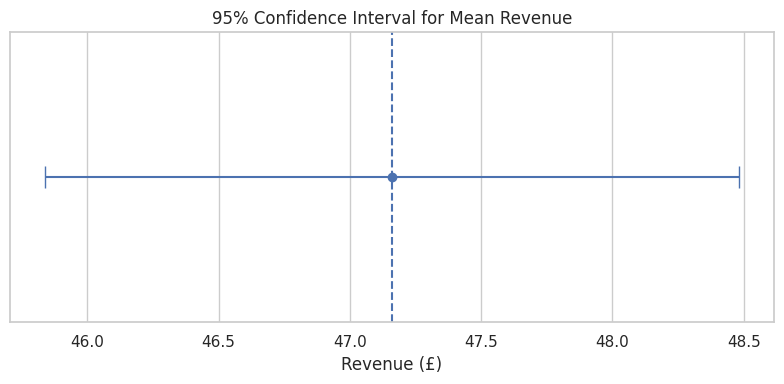

In [11]:
plt.figure(figsize=(8, 4))

plt.errorbar(
    x=[mean_revenue],
    y=[1],
    xerr=[margin_error],
    fmt="o",
    capsize=8
)

plt.axvline(
    mean_revenue,
    linestyle="--"
)

plt.title("95% Confidence Interval for Mean Revenue")
plt.xlabel("Revenue (£)")
plt.yticks([])
plt.tight_layout()
plt.show()

##  Hypothesis testing: discount and profit relationship

Use a Spearman correlation test to evaluate whether discounts and profits have a statistically significant monotonic relationship.
- \(H_0\): No monotonic relationship between discounts and profit.
- \(H_1\): A monotonic relationship exists between discounts and profit.

In [12]:
test_data = analysis_data[
    ["discount_pct", "net_profit_gbp"]
].dropna()

correlation, p_value = stats.spearmanr(
    test_data["discount_pct"],
    test_data["net_profit_gbp"]
)

print("Spearman correlation:", correlation)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Significant relationship found.")
else:
    print("Fail to reject H0: No statistically significant relationship detected.")

Spearman correlation: -0.17684803661110854
P-value: 6.57528251117881e-32
Reject H0: Significant relationship found.


##  Compare average revenue across two groups

Example: compare revenue for Prime and non-Prime customers, using Welch's t-test.

###  

In [15]:
# Print columns to debug the KeyError and find the correct Prime membership column
print("Available columns:", list(analysis_data.columns))

# Fallback/Update: Adjust the column name once you see the printed list.
# Common column names are 'is_prime', 'prime_member', 'prime', etc.
prime_col = [col for col in analysis_data.columns if "prime" in col.lower()]
if prime_col:
    col_name = prime_col[0]
    print(f"Using identified column: '{col_name}'")

    # Split groups using the identified column (handling both boolean and string types)
    group_a = analysis_data[
        (analysis_data[col_name] == "Yes") | (analysis_data[col_name] == True)
    ]["total_revenue_gbp"].dropna()

    group_b = analysis_data[
        (analysis_data[col_name] == "No") | (analysis_data[col_name] == False)
    ]["total_revenue_gbp"].dropna()

    print("Group A mean:", group_a.mean())
    print("Group B mean:", group_b.mean())

    t_statistic, p_value = stats.ttest_ind(
        group_a,
        group_b,
        equal_var=False
    )

    print("T statistic:", t_statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("There is a statistically significant difference in mean revenue.")
    else:
        print("There is insufficient evidence of a significant difference.")
else:
    print("No column containing 'prime' was found in the dataset. Please check the printed columns list above.")

Available columns: ['order_item_id', 'order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_list_price_gbp', 'discount_pct', 'unit_selling_price_gbp', 'shipping_mode', 'shipping_fee_gbp', 'payment_method', 'order_status', 'total_revenue_gbp', 'total_cost_gbp', 'net_profit_gbp', 'customer_rating', 'customer_name', 'region', 'is_prime_member', 'account_created_date', 'product_name', 'category', 'sub_category', 'brand', 'unit_cost_gbp', 'list_price_gbp', 'avg_rating', 'review_count', 'year', 'month', 'month_name', 'day', 'day_name', 'weekday', 'is_weekend', 'profit_margin_pct']
Using identified column: 'is_prime_member'
Group A mean: 46.97139578630549
Group B mean: 47.45762101534828
T statistic: -0.3556837146618806
P-value: 0.7220974588494755
There is insufficient evidence of a significant difference.


## Save statistical outputs

In [18]:
import os

os.makedirs(
    "/content/reports/figures/statistical_analysis",
    exist_ok=True
)

Save any charts created in this notebook using:

In [19]:
plt.savefig(
    "/content/reports/figures/statistical_analysis/chart.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>